# A testing of Hooke's law

## Our PHAS0007 module leader, Dr Jasvir Bhamrah, was testing Hooke’s Law by measuring the length of a spring with different masses attached to it. The Hooke’s Law states that $$F = kx$$ where 𝐹 is the tension in the spring, 𝑥 is the extension of the spring, and 𝑘 is the spring constant of the spring. Hence 𝑘 can be calculated from the gradient of a graph of extension vs the weight applied to the spring.

In the code below I will trying to plot a graph from 'spring.csv' which is measured by Dr Jasvir Bhamrah and then draw both weighted fit line and unweighted fit line for it. And finally carry out the value of k by F/x included its uncertainty

In [1]:
import numpy as np
import matplotlib.pyplot as plt

In [2]:
mass, extension, error = np.loadtxt(r'C:\Users\yaochuancy\Desktop\spring.csv',delimiter=',',unpack=True)
#I write this code in my own laptop, therefore the location is 'C:\Users\yaochuancy\Desktop\spring.csv'

In [3]:
degree = 1 

#set data for weighted fit
coeffs, errors = np.polyfit(mass,extension,degree,w=1/error,cov='unscaled')  # use cov='unscaled' for weighted fit
m, c = coeffs 
dm, dc = np.sqrt(np.diag(errors))

#set data for unweighted fit
coeffs_uw, errors_uw = np.polyfit(mass,extension,degree,cov=True) # use cov=True for unweighted fit
m_uw, c_uw = coeffs_uw                     # unpack gradient and intercept from output
dm_uw, dc_uw = np.sqrt(np.diag(errors_uw)) # errors are sqrt of diagonal terms

#Plotting code adapted from Unit 4 notes


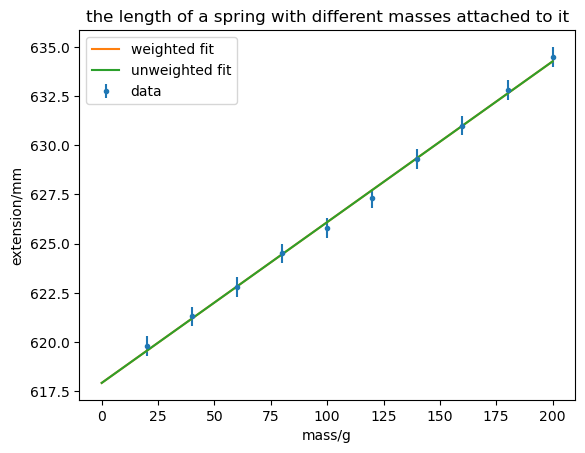

In [4]:
# Calculate coordinates to plot weighted fit line
xline = np.array([0,200])
yline_fit  = m * xline + c

# Calculate coordinates to plot unweighted fit line
yline_uw  = m_uw * xline + c_uw

# Set up graph
plt.figure()
plt.title("the length of a spring with different masses attached to it")
plt.xlabel("mass/g")
plt.ylabel("extension/mm")

# Plot weighted fit
plt.errorbar(mass,extension,yerr=error,fmt='.',label="data")
plt.plot(xline,yline_fit,'-',label='weighted fit')

#Plot unweighted fit
plt.plot(xline,yline_uw,'-',label='unweighted fit')

#Plotting code adapted from Unit 4 notes


plt.legend();

In [5]:
print('weighted fit line')
print(f"gradient m = {m} ± {dm} mm/g")
print(f"y-intercept c = {c} ± {dc} mm")

print('unweighted fit line')
print(f"gradient m = {m_uw} ± {dm_uw} mm/g")
print(f"y-intercept c = {c_uw} ± {dc_uw} mm")

weighted fit line
gradient m = 0.08172727272727331 ± 0.002752409412815904 mm/g
y-intercept c = 617.9199999999998 ± 0.3415650255319868 mm
unweighted fit line
gradient m = 0.08172727272727331 ± 0.0012770489397401603 mm/g
y-intercept c = 617.9199999999998 ± 0.1584776057213403 mm


In [6]:
print('weighted fit line')
print(f"gradient = {m:.3f} ± {dm:.3f} mm/g")
print(f"y-intercept c = {c:.0f} ± {dc:.2f} mm")

print('unweighted fit line')
print(f"gradient = {m_uw:.3f} ± {dm_uw:.3f} mm/g")
print(f"y-intercept c = {c_uw:.0f} ± {dc_uw:.2f} mm")

weighted fit line
gradient = 0.082 ± 0.003 mm/g
y-intercept c = 618 ± 0.34 mm
unweighted fit line
gradient = 0.082 ± 0.001 mm/g
y-intercept c = 618 ± 0.16 mm


## The difference shows that weighted fitting gives more realistic uncertainty estimates while unweighted fitting is overly optimistic as weighted fitting provides larger, more conservative errors.

## As the errors are the same, therefore the graphs of both weighted and unweighted fit line are the same, but with different values of uncertainty

In [7]:
g = 9.81

# For weighted fit
k = g / m  # N/m (since m is in mm/g = m/kg 
dk = k * (dm / m) 

# For unweighted fit  
k_uw = g / m_uw
dk_uw = k_uw * (dm_uw / m_uw)

print("Spring constant results:")
print(f"Weighted fit: k = {k:.0f} ± {dk:.0f} N/m")
print(f"Unweighted fit: k = {k_uw:.0f} ± {dk_uw:.0f} N/m")

Spring constant results:
Weighted fit: k = 120 ± 4 N/m
Unweighted fit: k = 120 ± 2 N/m


# Overall, the spring constant 𝑘 was determined using both weighted and unweighted linear regression. The weighted fit gave 𝑘 = 120 ± 4 N/m, while the unweighted fit gave 𝑘 = 120 ± 2 N/m.